# WLASL-100 video preprocessing

This notebook turns the acquired WLASL-100 clips into consistent RGB frame sequences for a
signer-independent isolated-sign recognition experiment. It bridges video acquisition and the
next notebook's MediaPipe landmark extraction; it does **not** run MediaPipe or train a model.

Videos vary in duration, dimensions, and availability. The pipeline therefore audits files on
disk, samples each usable clip deterministically across its full temporal extent, and letterboxes
frames so hands, face, and upper-body motion are not distorted or cropped. It writes compressed
per-video sequences plus an audit, manifest, and summary that make missing/corrupt inputs explicit.

## 1. Imports and environment configuration

Set `PROJECT_DIR` only when automatic root discovery cannot find the repository. Root discovery
checks that the official WLASL JSON exists, so execution does not depend on the notebook's working
directory.

In [1]:
from pathlib import Path
import json
import os
import tempfile
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

PROJECT_DIR = None  # e.g. Path('/path/to/sign-language-recognition'); otherwise auto-detect

def find_project_root(override=None):
    marker = Path('WLASL/start_kit/WLASL_v0.3.json')
    candidates = []
    if override:
        candidates.append(Path(override).expanduser())
    candidates.append(Path.home() / 'sign-language-recognition')
    here = Path.cwd().resolve()
    candidates.extend([here, *here.parents])
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / marker).is_file():
            return candidate
    raise FileNotFoundError(
        'Could not find project root containing WLASL/start_kit/WLASL_v0.3.json. '
        'Set PROJECT_DIR to the repository root.'
    )

PROJECT_ROOT = find_project_root(PROJECT_DIR)
DATA_DIR = PROJECT_ROOT / 'data/processed/WLASL100'
CLIPS_DIR = DATA_DIR / 'clips'
FRAMES_DIR = DATA_DIR / 'frames'
AUDIT_PATH = DATA_DIR / 'video_quality_audit.csv'
MANIFEST_PATH = DATA_DIR / 'preprocessing_manifest.csv'
SUMMARY_PATH = DATA_DIR / 'preprocessing_summary.json'
METADATA_PATHS = {split: DATA_DIR / f'{split}_metadata.csv' for split in ('train', 'val', 'test')}

print(f'Project root: {PROJECT_ROOT}')
print(f'Clips directory: {CLIPS_DIR}')
print('Metadata paths:')
for split, path in METADATA_PATHS.items():
    print(f'  {split}: {path}')
print(f'Output directory: {FRAMES_DIR}')

Project root: /Users/sahilchauhan/sign-language-recognition
Clips directory: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/clips
Metadata paths:
  train: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/train_metadata.csv
  val: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/val_metadata.csv
  test: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/test_metadata.csv
Output directory: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/frames


/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load frozen metadata and inventory available clips

The frozen CSVs are read as authoritative and are never rewritten. File availability is determined
from the filesystem, not acquisition logs. Canonical WLASL IDs remain strings; a zero-padding-tolerant
lookup is used only to match legacy filenames.

In [2]:

from itertools import combinations

REQUIRED_COLUMNS = {'video_id', 'gloss', 'signer_id'}
VIDEO_EXTENSIONS = {'.mp4', '.mov', '.mkv', '.avi', '.webm'}


def read_frozen_metadata(paths):
    tables = []

    for split, path in paths.items():
        if not path.is_file():
            raise FileNotFoundError(
                f'Frozen {split} metadata is missing: {path}'
            )

        table = pd.read_csv(
            path,
            dtype={'video_id': 'string', 'signer_id': 'string',
                   'gloss': 'string'}
        )

        missing = REQUIRED_COLUMNS - set(table.columns)
        if missing:
            raise ValueError(
                f'{path.name} missing required columns: {sorted(missing)}'
            )

        # Validate missing values BEFORE string conversion/normalization.
        for column in REQUIRED_COLUMNS:
            if table[column].isna().any():
                raise ValueError(
                    f'{path.name} contains missing values in {column}'
                )

            table[column] = table[column].str.strip()

            if table[column].eq('').any():
                raise ValueError(
                    f'{path.name} contains empty values in {column}'
                )

        if table['video_id'].duplicated().any():
            raise ValueError(
                f'{path.name} contains duplicate video IDs'
            )

        table['experimental_split'] = split
        tables.append(table)

    metadata = pd.concat(tables, ignore_index=True)

    if metadata['video_id'].duplicated().any():
        duplicate_ids = metadata.loc[
            metadata['video_id'].duplicated(keep=False),
            'video_id'
        ].unique()[:10]

        raise ValueError(
            f'Duplicate instances across frozen splits: '
            f'{duplicate_ids.tolist()}'
        )

    # Verify signer independence across every pair of splits.
    signer_sets = {
        split: set(
            metadata.loc[
                metadata['experimental_split'].eq(split), 'signer_id'
            ]
        )
        for split in paths
    }

    for left, right in combinations(signer_sets, 2):
        overlap = signer_sets[left] & signer_sets[right]

        if overlap:
            raise ValueError(
                f'Signer leakage between {left} and {right}: '
                f'{sorted(overlap)}'
            )

    return metadata


def canonical_key(video_id):
    value = str(video_id).strip()
    return value.lstrip('0') or '0'


def build_clip_index(clips_dir):
    if not clips_dir.is_dir():
        print(f'Warning: clips directory does not exist yet: {clips_dir}')
        return {}, {}

    exact = {}
    relaxed = {}

    for path in clips_dir.iterdir():
        if not path.is_file() or path.suffix.lower() not in VIDEO_EXTENSIONS:
            continue

        exact.setdefault(path.stem, []).append(path)
        relaxed.setdefault(canonical_key(path.stem), []).append(path)

    # Reject ambiguous exact IDs instead of silently selecting a file.
    ambiguous = {
        key: paths for key, paths in exact.items()
        if len(paths) > 1
    }

    if ambiguous:
        examples = {
            key: [p.name for p in paths]
            for key, paths in list(ambiguous.items())[:10]
        }
        raise ValueError(f'Ambiguous clip filenames: {examples}')

    exact = {key: paths[0] for key, paths in exact.items()}

    return exact, relaxed


def resolve_clip(video_id, exact, relaxed):
    video_id = str(video_id).strip()

    if video_id in exact:
        return exact[video_id]

    candidates = relaxed.get(canonical_key(video_id), [])

    return candidates[0] if len(candidates) == 1 else None


# Build the instance inventory.
metadata = read_frozen_metadata(METADATA_PATHS)

exact_paths, relaxed_paths = build_clip_index(CLIPS_DIR)

inventory = metadata.copy()

inventory['source_instance_id'] = (
    inventory['instance_id'].astype('string')
    if 'instance_id' in inventory.columns
    else inventory['video_id']
)

inventory['clip_path'] = inventory['video_id'].map(
    lambda x: str(resolve_clip(x, exact_paths, relaxed_paths) or '')
)

inventory['file_exists'] = inventory['clip_path'].ne('')

print(f'Metadata instances: {len(inventory):,}')

display(
    inventory.groupby('experimental_split')['file_exists']
    .agg(['size', 'sum'])
    .rename(columns={
        'size': 'metadata_instances',
        'sum': 'available_clips'
    })
)


Metadata instances: 2,038


,metadata_instances,available_clips
experimental_split,,
test,611,317
train,1003,535
val,424,171


## 3. Video decoding and quality audit

OpenCV metadata is recorded separately from a successful first-frame decode. A corrupt or unreadable
file becomes an auditable row rather than stopping the run.

In [3]:
def inspect_video(path):
    result = {'opens': False, 'first_frame_decodes': False, 'reported_frame_count': np.nan, 'decoded_frame_count': 0,
              'fps': np.nan, 'width': np.nan, 'height': np.nan, 'duration_seconds': np.nan,
              'file_size_bytes': np.nan, 'error_reason': ''}
    try:
        path = Path(path)
        result['file_size_bytes'] = path.stat().st_size
        cap = cv2.VideoCapture(str(path))
        result['opens'] = bool(cap.isOpened())
        if not result['opens']:
            result['error_reason'] = 'opencv_could_not_open'
            return result
        result['reported_frame_count'] = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        result['fps'] = float(cap.get(cv2.CAP_PROP_FPS))
        result['width'] = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        result['height'] = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        if np.isfinite(result['fps']) and result['fps'] > 0 and result['reported_frame_count'] >= 0:
            result['duration_seconds'] = result['reported_frame_count'] / result['fps']
        ok, _ = cap.read()
        result['first_frame_decodes'] = bool(ok)
        if not ok:
            result['error_reason'] = 'first_frame_decode_failed'
        else:
            decoded = 1
            while True:
                ok, _ = cap.read()
                if not ok:
                    break
                decoded += 1
            result['decoded_frame_count'] = decoded
        cap.release()
    except Exception as exc:
        result['error_reason'] = f'{type(exc).__name__}: {exc}'
    return result

audit_rows = []
for row in tqdm(inventory.itertuples(index=False), total=len(inventory), desc='Auditing clips'):
    details = inspect_video(row.clip_path) if row.file_exists else {'opens': False, 'first_frame_decodes': False, 'reported_frame_count': np.nan, 'decoded_frame_count': 0, 'fps': np.nan, 'width': np.nan, 'height': np.nan, 'duration_seconds': np.nan, 'file_size_bytes': np.nan, 'error_reason': 'clip_missing'}
    audit_rows.append({**row._asdict(), **details})
audit = pd.DataFrame(audit_rows)
DATA_DIR.mkdir(parents=True, exist_ok=True)
audit.to_csv(AUDIT_PATH, index=False)
print(f'Saved audit: {AUDIT_PATH}')
display(audit.groupby('experimental_split')['first_frame_decodes'].agg(['size', 'sum']))

Auditing clips: 100%|██████████| 2038/2038 [00:56<00:00, 36.22it/s]

Saved audit: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/video_quality_audit.csv


,size,sum
experimental_split,,
test,611,317
train,1003,535
val,424,171


## 4. Preprocessing configuration

Thirty-two uniformly spaced frames give a compact starting representation of an isolated sign while
covering onset, motion, and endpoint. It is an experimental design choice, not a universal optimum.
Frames are saved as compact `uint8` RGB; normalize to `[0, 1]` later only when a consumer needs it.

In [4]:
TARGET_FRAMES = 32
FRAME_SIZE = (256, 256)  # (width, height)
SAVE_FRAME_SEQUENCES = True
OVERWRITE_EXISTING = False
MAX_VIDEOS = None
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

assert TARGET_FRAMES > 0 and all(d > 0 for d in FRAME_SIZE)
print({'target_frames': TARGET_FRAMES, 'frame_size': FRAME_SIZE, 'dtype': 'uint8 RGB'})

{'target_frames': 32, 'frame_size': (256, 256), 'dtype': 'uint8 RGB'}


## 5. Temporal sampling and spatial preprocessing

Sampling uses `linspace` from frame 0 through the final decodable frame, preserving order and both
ends. Short videos repeat indices; failed reads are reported as errors rather than replaced by black
frames. Letterboxing preserves aspect ratio and uses black padding without random crops or flips.

In [5]:
def uniform_indices(frame_count, target_frames=TARGET_FRAMES):
    if frame_count < 1:
        raise ValueError('frame_count must be at least 1')
    return np.linspace(0, frame_count - 1, target_frames, dtype=np.int64)

def letterbox_rgb(frame_bgr, frame_size=FRAME_SIZE):
    if frame_bgr is None or frame_bgr.ndim != 3 or frame_bgr.shape[2] != 3:
        raise ValueError('Expected a three-channel BGR frame')
    target_w, target_h = frame_size
    source_h, source_w = frame_bgr.shape[:2]
    scale = min(target_w / source_w, target_h / source_h)
    new_w, new_h = max(1, round(source_w * scale)), max(1, round(source_h * scale))
    resized = cv2.resize(frame_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    canvas = np.zeros((target_h, target_w, 3), dtype=np.uint8)
    x0, y0 = (target_w - new_w) // 2, (target_h - new_h) // 2
    canvas[y0:y0 + new_h, x0:x0 + new_w] = resized
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)

def decode_frames(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError('opencv_could_not_open')
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(frame)
    cap.release()
    if not frames:
        raise RuntimeError('no_frames_decoded')
    return frames

def preprocess_video(path, target_frames=TARGET_FRAMES, frame_size=FRAME_SIZE):
    decoded = decode_frames(path)
    indices = uniform_indices(len(decoded), target_frames)
    sequence = np.stack([letterbox_rgb(decoded[i], frame_size) for i in indices], axis=0)
    expected = (target_frames, frame_size[1], frame_size[0], 3)
    if sequence.shape != expected or sequence.dtype != np.uint8:
        raise RuntimeError(f'Unexpected sequence output: {sequence.shape}, {sequence.dtype}')
    return sequence, indices, len(decoded)

def output_is_valid(path):
    try:
        with np.load(path) as saved:
            sequence = saved['frames']
        return sequence.shape == (TARGET_FRAMES, FRAME_SIZE[1], FRAME_SIZE[0], 3) and sequence.dtype == np.uint8
    except Exception:
        return False

def atomic_save_npz(destination, frames):
    destination.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=destination.parent, suffix='.npz', delete=False) as handle:
        temporary = Path(handle.name)
    try:
        np.savez_compressed(temporary, frames=frames)
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()

## 6. Process all available clips

The loop processes one clip at a time and atomically saves `frames/<canonical_video_id>.npz`.
Existing valid outputs are retained unless overwrite is explicitly enabled. The resulting manifest
records every metadata row—including missing, invalid, skipped, and failed examples.

In [6]:
processing_rows = []
eligible = audit.loc[audit['first_frame_decodes'].fillna(False)].copy()
if MAX_VIDEOS is not None:
    eligible = eligible.head(MAX_VIDEOS)
eligible_ids = set(eligible['video_id'])

for row in tqdm(audit.itertuples(index=False), total=len(audit), desc='Preprocessing clips'):
    record = {'video_id': row.video_id, 'source_instance_id': row.source_instance_id, 'gloss': row.gloss, 'signer_id': row.signer_id,
              'experimental_split': row.experimental_split, 'clip_path': row.clip_path,
              'file_exists': row.file_exists, 'audit_valid': row.first_frame_decodes,
              'output_path': '', 'processing_status': '', 'error_reason': '',
              'decoded_frame_count': np.nan, 'sampled_indices': ''}
    if not row.file_exists:
        record.update(processing_status='missing_clip', error_reason='clip_missing')
    elif not bool(row.first_frame_decodes):
        record.update(processing_status='invalid_clip', error_reason=row.error_reason or 'audit_failed')
    elif row.video_id not in eligible_ids:
        record.update(processing_status='not_selected_by_max_videos', error_reason='MAX_VIDEOS limit')
    else:
        destination = FRAMES_DIR / f'{row.video_id}.npz'
        record['output_path'] = str(destination)
        try:
            if destination.exists() and not OVERWRITE_EXISTING and output_is_valid(destination):
                record['processing_status'] = 'skipped_existing_valid'
            else:
                frames, indices, decoded_count = preprocess_video(row.clip_path)
                if SAVE_FRAME_SEQUENCES:
                    atomic_save_npz(destination, frames)
                record.update(processing_status='processed', decoded_frame_count=decoded_count,
                              sampled_indices=json.dumps(indices.tolist()))
        except Exception as exc:
            record.update(processing_status='failed', error_reason=f'{type(exc).__name__}: {exc}')
    processing_rows.append(record)

manifest = pd.DataFrame(processing_rows)
manifest.to_csv(MANIFEST_PATH, index=False)
print(f'Saved manifest: {MANIFEST_PATH}')
display(manifest.groupby(['experimental_split', 'processing_status']).size().unstack(fill_value=0))

Preprocessing clips: 100%|██████████| 2038/2038 [02:27<00:00, 13.83it/s]

Saved manifest: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/preprocessing_manifest.csv


processing_status,missing_clip,processed,skipped_existing_valid
experimental_split,,,
test,294,73,244
train,468,353,182
val,253,140,31


## 7. Visual quality checks

These compact plots are conditional: no visualization assumes that any particular clip exists.

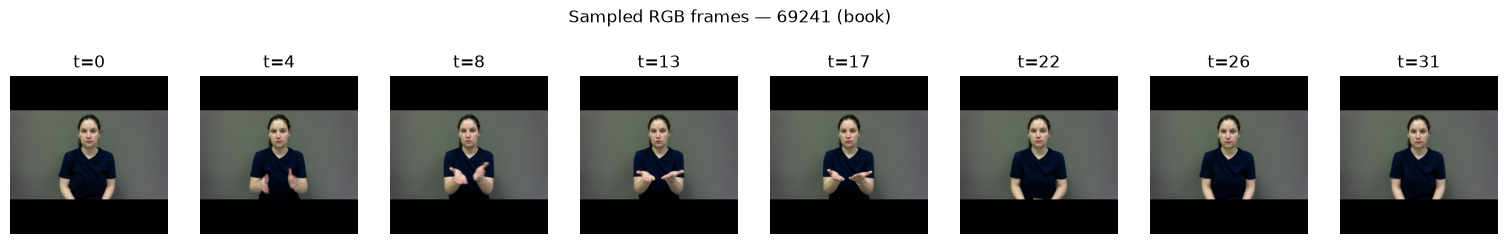

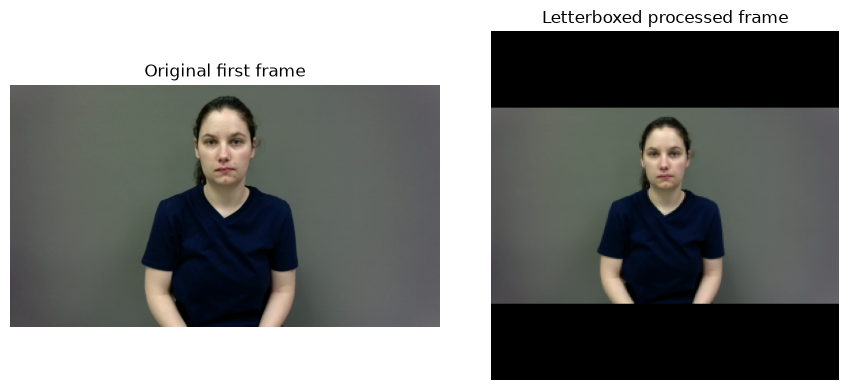

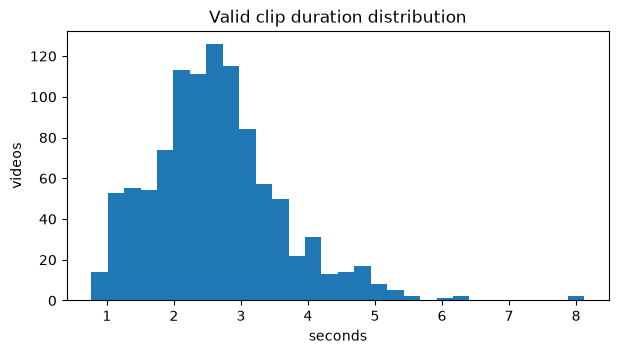

Shortest audited valid clip: 06334 (19.0 reported frames)


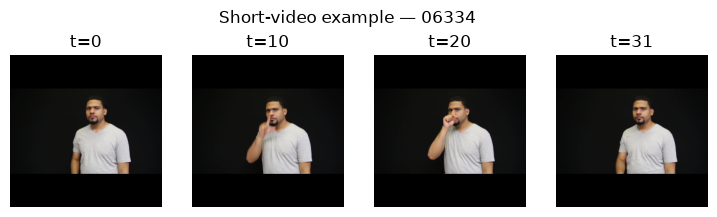

In [7]:
successful = manifest.loc[manifest.processing_status.isin(['processed', 'skipped_existing_valid'])].copy()

def load_sequence(path):
    with np.load(path) as data:
        return data['frames']

if not successful.empty:
    example = successful.iloc[0]
    sequence = load_sequence(example.output_path)
    picks = np.unique(np.linspace(0, len(sequence) - 1, min(8, len(sequence)), dtype=int))
    fig, axes = plt.subplots(1, len(picks), figsize=(2.4 * len(picks), 3))
    axes = np.atleast_1d(axes)
    for ax, idx in zip(axes, picks):
        ax.imshow(sequence[idx])
        ax.set_title(f't={idx}')
        ax.axis('off')
    fig.suptitle(f"Sampled RGB frames — {example.video_id} ({example.gloss})")
    plt.show()

    raw = decode_frames(example.clip_path)[0]
    processed = sequence[0]
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)); axes[0].set_title('Original first frame'); axes[0].axis('off')
    axes[1].imshow(processed); axes[1].set_title('Letterboxed processed frame'); axes[1].axis('off')
    plt.tight_layout(); plt.show()
else:
    print('No successfully preprocessed videos are available for frame visualizations.')

valid_durations = audit.loc[audit.first_frame_decodes.fillna(False), 'duration_seconds'].dropna()
if not valid_durations.empty:
    plt.figure(figsize=(7, 3.5)); plt.hist(valid_durations, bins=min(30, max(5, len(valid_durations))))
    plt.title('Valid clip duration distribution'); plt.xlabel('seconds'); plt.ylabel('videos'); plt.show()
short = audit.loc[audit.first_frame_decodes.fillna(False)].sort_values('reported_frame_count').head(1)
if not short.empty:
    print(f"Shortest audited valid clip: {short.iloc[0].video_id} ({short.iloc[0].reported_frame_count} reported frames)")
    short_id = short.iloc[0].video_id
    short_output = successful.loc[successful.video_id.eq(short_id), 'output_path']
    if not short_output.empty:
        short_sequence = load_sequence(short_output.iloc[0])
        fig, axes = plt.subplots(1, 4, figsize=(9, 2.5))
        for ax, idx in zip(axes, np.linspace(0, len(short_sequence) - 1, 4, dtype=int)):
            ax.imshow(short_sequence[idx]); ax.set_title(f't={idx}'); ax.axis('off')
        fig.suptitle(f'Short-video example — {short_id}')
        plt.show()

## 8. Dataset preprocessing statistics

Statistics below describe real filesystem and processing outcomes. “Usable” means a valid processed
sequence exists (created now or verified from a prior run); it is never inferred from metadata alone.

In [8]:
manifest['usable'] = manifest['processing_status'].isin(['processed', 'skipped_existing_valid']) & manifest['output_path'].map(lambda p: bool(p) and output_is_valid(Path(p)))
all_classes = set(metadata['gloss'])
coverage = []
for split in ('train', 'val', 'test'):
    subset = manifest.loc[manifest.experimental_split.eq(split)]
    usable_classes = set(subset.loc[subset.usable, 'gloss'])
    coverage.append({'split': split, 'metadata_instances': int(len(subset)), 'available_videos': int(subset.file_exists.sum()),
                     'valid_videos': int(subset.audit_valid.fillna(False).sum()), 'usable_sequences': int(subset.usable.sum()),
                     'failed_preprocessing': int(subset.processing_status.eq('failed').sum()),
                     'classes_represented': int(len(usable_classes)), 'missing_classes': sorted(all_classes - usable_classes)})
summary = {
    'preprocessing_parameters': {'target_frames': TARGET_FRAMES, 'frame_size_width_height': list(FRAME_SIZE), 'output_dtype': 'uint8', 'color_order': 'RGB', 'temporal_sampling': 'uniform linspace including endpoints; repeated indices for short clips', 'spatial_handling': 'aspect-ratio-preserving letterbox; black padding; no flips or random crop'},
    'total_metadata_instances': int(len(manifest)), 'available_videos': int(manifest.file_exists.sum()),
    'valid_videos': int(manifest.audit_valid.fillna(False).sum()), 'successfully_preprocessed_videos': int(manifest.usable.sum()),
    'failed_preprocessing_instances': int(manifest.processing_status.eq('failed').sum()), 'coverage_by_split': coverage,
    'coverage_by_gloss': manifest.groupby('gloss')['usable'].agg(metadata_instances='size', usable_sequences='sum').reset_index().to_dict(orient='records'),
}
with open(SUMMARY_PATH, 'w', encoding='utf-8') as handle:
    json.dump(summary, handle, indent=2)
manifest.to_csv(MANIFEST_PATH, index=False)
print(json.dumps({k: v for k, v in summary.items() if k not in {'coverage_by_gloss', 'coverage_by_split'}}, indent=2))
display(pd.DataFrame(coverage).drop(columns='missing_classes'))
print(f'Saved: {MANIFEST_PATH}\nSaved: {SUMMARY_PATH}')

{
  "preprocessing_parameters": {
    "target_frames": 32,
    "frame_size_width_height": [
      256,
      256
    ],
    "output_dtype": "uint8",
    "color_order": "RGB",
    "temporal_sampling": "uniform linspace including endpoints; repeated indices for short clips",
    "spatial_handling": "aspect-ratio-preserving letterbox; black padding; no flips or random crop"
  },
  "total_metadata_instances": 2038,
  "available_videos": 1023,
  "valid_videos": 1023,
  "successfully_preprocessed_videos": 1023,
  "failed_preprocessing_instances": 0
}


,split,metadata_instances,available_videos,valid_videos,usable_sequences,failed_preprocessing,classes_represented
0,train,1003,535,535,535,0,100
1,val,424,171,171,171,0,91
2,test,611,317,317,317,0,98


Saved: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/preprocessing_manifest.csv
Saved: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/preprocessing_summary.json


## 9. Lightweight synthetic validation

This self-contained check exercises temporal indices, portrait/landscape letterboxing, compressed
save/reload, and missing/corrupt input handling without creating dummy WLASL outputs. It does not
claim that real WLASL clips were executed in this environment.

In [9]:
def run_synthetic_checks():
    for shape in ((480, 240, 3), (240, 480, 3)):
        image = np.full(shape, 127, dtype=np.uint8)
        boxed = letterbox_rgb(image)
        assert boxed.shape == (FRAME_SIZE[1], FRAME_SIZE[0], 3) and boxed.dtype == np.uint8
    with tempfile.TemporaryDirectory() as temp_dir:
        temp = Path(temp_dir)
        for count in (1, 10, 32, 100):
            video = temp / f'{count}_frames.avi'
            writer = cv2.VideoWriter(str(video), cv2.VideoWriter_fourcc(*'MJPG'), 12, (48, 32))
            assert writer.isOpened(), 'OpenCV could not create synthetic test video'
            for index in range(count):
                writer.write(np.full((32, 48, 3), index % 255, dtype=np.uint8))
            writer.release()
            frames, idx, decoded_count = preprocess_video(video)
            assert decoded_count == count and len(idx) == TARGET_FRAMES
            assert idx[0] == 0 and idx[-1] == count - 1 and np.all(np.diff(idx) >= 0)
            assert frames.shape == (TARGET_FRAMES, FRAME_SIZE[1], FRAME_SIZE[0], 3) and frames.dtype == np.uint8
        sequence = np.zeros((TARGET_FRAMES, FRAME_SIZE[1], FRAME_SIZE[0], 3), dtype=np.uint8)
        saved = temp / 'sequence.npz'; atomic_save_npz(saved, sequence)
        assert output_is_valid(saved)
        try:
            preprocess_video(temp / 'missing.mp4')
            raise AssertionError('missing video unexpectedly processed')
        except RuntimeError:
            pass
        bad = temp / 'corrupt.mp4'; bad.write_bytes(b'not a video')
        assert not inspect_video(bad)['first_frame_decodes']
    return 'Synthetic checks passed.'

print(run_synthetic_checks())

Synthetic checks passed.


OpenCV: Couldn't read video stream from file "/var/folders/sv/qsh8nfp908z0x4hjly1q7tw40000gn/T/tmpqb2ww_ec/missing.mp4"
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x78f93ed680] moov atom not found
OpenCV: Couldn't read video stream from file "/var/folders/sv/qsh8nfp908z0x4hjly1q7tw40000gn/T/tmpqb2ww_ec/corrupt.mp4"


## 10. Reproducibility and next steps

The manifest is the downstream source of truth: Notebook 04 should select only rows where `usable`
is true, load `frames` from each `.npz` as `(32, 256, 256, 3)` `uint8` RGB, and then run MediaPipe
landmark extraction. Convert to float `[0, 1]` only if that extractor or a model requires it.

The frozen split is never regenerated. Deterministic endpoint-inclusive sampling, configured output
size, black letterboxing, and the recorded random seed are saved in `preprocessing_summary.json`.
Limitations include missing/private source videos, OpenCV codec support, no temporal alignment beyond
uniform sampling, and no semantic-changing augmentation. Reruns preserve valid outputs unless
`OVERWRITE_EXISTING` is deliberately enabled.